## Import packages

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import pathlib
import torch
import torch.nn as nn
from datasets import Dataset, DatasetDict
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding, pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt


import warnings
warnings.filterwarnings("ignore")

## Inputs

In [2]:
INPUT_DIR = pathlib.Path("/kaggle/input")

COMPETITIONS_DIR = sorted([
    p for p in (INPUT_DIR / "competitions").iterdir()
    if p.is_dir()
])

DATASET_DIR = sorted([
    p for p in (INPUT_DIR / "datasets").iterdir()
    if p.is_dir()
])

MODEL_DIR = sorted([
    p for p in (INPUT_DIR / "models").iterdir()
    if p.is_dir()
])


print("Competitions directories:", len(COMPETITIONS_DIR))
for path in COMPETITIONS_DIR:
    for file_path in path.rglob("*"):
        if file_path.is_file():
            path_str = str(file_path)
            print(path_str)
    
print("\nDataset directories:", len(DATASET_DIR))
for path in DATASET_DIR:
    print(path)

print("\nModel directories:", len(MODEL_DIR))
for path in MODEL_DIR:
    print(path)

Competitions directories: 1
/kaggle/input/competitions/name-that-llm/sample_submission.parquet
/kaggle/input/competitions/name-that-llm/train.csv
/kaggle/input/competitions/name-that-llm/test.csv

Dataset directories: 8
/kaggle/input/datasets/abdullah1afify
/kaggle/input/datasets/crtproduction
/kaggle/input/datasets/dhruvtibarewal
/kaggle/input/datasets/dophuchung
/kaggle/input/datasets/lucasboesen
/kaggle/input/datasets/nishantdahal
/kaggle/input/datasets/nuridudak
/kaggle/input/datasets/seyitkaangunes

Model directories: 1
/kaggle/input/models/answer-ai


## Read the datasets

In [3]:
# competitions training data
TRAIN_PATH = (
    INPUT_DIR / "competitions/name-that-llm/train.csv"
)

# Original competition dataset
train_df = pd.read_csv(TRAIN_PATH)
print("Original training shape:", train_df.shape)
print("Columns:", train_df.columns.tolist())
print("Classes:", train_df["model"].nunique())

VALID_LABELS = set(train_df["model"].dropna().unique())
train_df.head()

Original training shape: (2699, 4)
Columns: ['id', 'prompt_id', 'text', 'model']
Classes: 18


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


### Extra Data

In [4]:
# Candidate text and label column names
TEXT_COLUMNS = ["text", "response", "passage", "completion", "content"]
LABEL_COLUMNS = ["model", "model_name", "label", "source_model"]

reports = []
usable_files = []
invalid_dirs = []

for directory in DATASET_DIR:

    if not directory.exists():
        invalid_dirs.append(directory)
        continue

    valid_files = []

    for path in directory.rglob("*"):

        if path.suffix.lower() not in [".csv", ".parquet"]:
            continue

        try:
            if path.suffix.lower() == ".csv":
                df = pd.read_csv(path)
            else:
                df = pd.read_parquet(path)

            text_col = next(
                (c for c in TEXT_COLUMNS if c in df.columns),
                None
            )

            label_col = next(
                (c for c in LABEL_COLUMNS if c in df.columns),
                None
            )

            if text_col is None or label_col is None:
                continue

            labels = set(df[label_col].dropna().astype(str))

            matching_labels = labels.intersection(VALID_LABELS)

            matching_rows = df[
                df[label_col].astype(str).isin(VALID_LABELS)
                & df[text_col].notna()
            ]

            reports.append({
                "directory": directory.name,
                "file": path.name,
                "rows": len(df),
                "text_column": text_col,
                "label_column": label_col,
                "matching_classes": len(matching_labels),
                "matching_rows": len(matching_rows),
                "usable": len(matching_rows) > 0
            })

            if len(matching_rows) > 0:
                usable_files.append((path, text_col, label_col))
                valid_files.append(path)

        except Exception as e:
            print("Skipped:", path.name, str(e)[:100])

    # Directory is invalid if no usable file was found
    if not valid_files:
        invalid_dirs.append(directory)

# Display report
report_df = pd.DataFrame(reports)

if not report_df.empty:
    display(
        report_df.sort_values(
            "matching_rows",
            ascending=False
        )
    )

print("\nPotentially usable files:", len(usable_files))

print("\nInvalid directories:", len(invalid_dirs))
for directory in invalid_dirs:
    print(directory)

,directory,file,rows,text_column,label_column,matching_classes,matching_rows,usable
4,crtproduction,ntl_open_pool.parquet,212623,text,model,18,212623,True
7,dhruvtibarewal,nlm_pool_v5.parquet,119899,text,model,18,119899,True
6,dhruvtibarewal,nlm_pool_v2.parquet,37252,text,model,18,37252,True
10,nishantdahal,pool_v1.parquet,34940,text,model,18,34940,True
5,dhruvtibarewal,nlm_matched_clean.parquet,24443,text,model,18,24443,True
3,crtproduction,gemini37_unverified.parquet,10838,text,model,1,10838,True
9,lucasboesen,gen_passages.csv,7906,text,model,8,7906,True
2,abdullah1afify,ntl_generations.csv,5726,text,label,8,5726,True
11,seyitkaangunes,ntl_extra_passages_claude.csv,4998,text,model,5,4998,True
0,abdullah1afify,ntl_claude_plain.csv,4995,text,label,5,4995,True



Potentially usable files: 12

Invalid directories: 1
/kaggle/input/datasets/nuridudak


In [5]:
# Start with original competition training data
consolidated_dfs = [
    train_df[["text", "model"]].copy()
]

for path, text_col, label_col in usable_files:

    try:
        if path.suffix.lower() == ".csv":
            df = pd.read_csv(path)
        else:
            df = pd.read_parquet(path)

        # Keep only valid labels and non-empty text
        temp_df = df[[text_col, label_col]].copy()

        temp_df.columns = ["text", "model"]

        temp_df = temp_df.dropna(subset=["text", "model"])

        temp_df["text"] = temp_df["text"].astype(str).str.strip()
        temp_df["model"] = temp_df["model"].astype(str).str.strip()

        temp_df = temp_df[
            temp_df["model"].isin(VALID_LABELS)
            & (temp_df["text"] != "")
        ]

        consolidated_dfs.append(temp_df)

    except Exception as e:
        print(f"Error processing {path}: {e}")

# Combine all datasets
consolidated_df = pd.concat(
    consolidated_dfs,
    ignore_index=True
)

# Remove exact duplicate text-model pairs
consolidated_df = consolidated_df.drop_duplicates(
    subset=["text", "model"]
).reset_index(drop=True)

print("Consolidated shape:", consolidated_df.shape)
print("Columns:", consolidated_df.columns.tolist())
print("Unique classes:", consolidated_df["model"].nunique())

display(consolidated_df.head())

Consolidated shape: (248377, 2)
Columns: ['text', 'model']
Unique classes: 18


,text,model
0,"When a language dies, a particular astronomy d...",qwen3.8-max
1,Data science communities matter because they a...,claude-sonnet-5
2,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,Data science communities matter because they t...,gpt-5.6-terra
4,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [6]:
consolidated_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 248377 entries, 0 to 248376
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    248377 non-null  object
 1   model   248377 non-null  object
dtypes: object(2)
memory usage: 3.8+ MB


In [7]:
consolidated_df.describe()

,text,model
count,248377,248377
unique,248377,18
top,"The ""Is-Ought Problem,"" famously dubbed Hume’s...",gemini-3.8-flash
freq,1,24537


In [8]:
train_df.describe()

,id,prompt_id,text,model
count,2699,2699,2699,2699
unique,2699,150,2699,18
top,ffeb7ecdc58a,p081,"Consider the instant — if ""instant"" means anyt...",qwen3.8-max
freq,1,18,1,150


In [9]:
consolidated_df.model.value_counts()

model
gemini-3.8-flash          24537
gemini-3.6-flash          19132
gpt-5.6-luna              18817
gpt-5.6-terra             15937
gemini-3.7-flash          15783
glm-5.3-flash             15620
gpt-5.6-sol               15289
glm-5.3                   14384
gpt-5.5                   13559
claude-fable-5            13385
claude-sonnet-5           12612
claude-opus-4-8           11743
gpt-6-astra               11166
gemini-3.1-pro-preview    11096
claude-opus-4-6           10746
kimi-k3                   10662
claude-opus-5              8838
qwen3.8-max                5071
Name: count, dtype: int64

## Prepare the datasets

In [10]:
df = consolidated_df[['text','model']]
print(df.shape)
print('CHAR LENGTH:',len(df.iloc[0]['text']))
print(df.iloc[0]['text'])

(248377, 2)
CHAR LENGTH: 1143
When a language dies, a particular astronomy dims: not only names for stars, but whole grammars of attention that taught speakers how to read the night. Some tongues map the sky by kinship, binding the Milky Way to ancestors, rivers, or the migration paths of birds; others encode lunar phases as verbs, so time is not a line but a recurring breath. A word can carry the exact color of dawn on snow, the etiquette of speaking to thunder, or the mathematics woven into knot calendars and oral star charts. With extinction, those relations collapse into silence. No dictionary can resurrect the sky those speakers inhabited, nor the quiet ethics it taught. We lose metaphors that made the universe intimate, ethical, and alive, cosmologies in which darkness is a listener, comets are warnings carried by relatives, and constellations are not fixed pictures but seasonal responsibilities. The loss is not merely lexical; it is the erasure of possible human answers to wonde

In [11]:
# # Take at least one sample from each model
# df_first = df.groupby('model', group_keys=False).head(1)

# # Sample remaining rows randomly
# remaining = df.drop(df_first.index)

# df_rest = remaining.sample(
#     n=300 - len(df_first),
#     random_state=42
# )

# # Combine and shuffle
# df = pd.concat([df_first, df_rest]).sample(
#     frac=1,
#     random_state=42
# ).reset_index(drop=True)

# print(df.shape)
# print(df['model'].value_counts())

In [12]:
# Convert your pandas DataFrame into a Hugging Face Dataset
ds = Dataset.from_pandas(
    df,
    preserve_index=False
)

ds

Dataset({
    features: ['text', 'model'],
    num_rows: 248377
})

### Label Encoding

In [13]:
# Encode model names as ClassLabel
ds = ds.class_encode_column("model")
ds.features

Casting to class labels:   0%|          | 0/248377 [00:00<?, ? examples/s]

{'text': Value('string'),
 'model': ClassLabel(names=['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5', 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'glm-5.3', 'glm-5.3-flash', 'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra', 'kimi-k3', 'qwen3.8-max'])}

In [14]:
class_label = ds.features["model"]

# Number of classification labels
num_labels = class_label.num_classes

# Create mappings
id2label = {
    idx: name
    for idx, name in enumerate(class_label.names)
}

label2id = {
    name: idx
    for idx, name in id2label.items()
}

print("Number of classes:", num_labels)
print("ID -> Model Name:")
display(id2label)

Number of classes: 18
ID -> Model Name:


{0: 'claude-fable-5',
 1: 'claude-opus-4-6',
 2: 'claude-opus-4-8',
 3: 'claude-opus-5',
 4: 'claude-sonnet-5',
 5: 'gemini-3.1-pro-preview',
 6: 'gemini-3.6-flash',
 7: 'gemini-3.7-flash',
 8: 'gemini-3.8-flash',
 9: 'glm-5.3',
 10: 'glm-5.3-flash',
 11: 'gpt-5.5',
 12: 'gpt-5.6-luna',
 13: 'gpt-5.6-sol',
 14: 'gpt-5.6-terra',
 15: 'gpt-6-astra',
 16: 'kimi-k3',
 17: 'qwen3.8-max'}

### Split the dataset into Train, Test and Validations

In [15]:
# First split: 70% train, 30% temporary
split1 = ds.train_test_split(
    test_size=0.3,
    seed=42,
    stratify_by_column="model"
)


dataset_splits = DatasetDict({
    "train": split1["train"],
    "validation": split1["test"],
})

print(dataset_splits)

DatasetDict({
    train: Dataset({
        features: ['text', 'model'],
        num_rows: 173863
    })
    validation: Dataset({
        features: ['text', 'model'],
        num_rows: 74514
    })
})


## Load the Model

In [16]:
if torch.cuda.is_available():
  print("Is GPU available?", True)
  print("Device count:", torch.cuda.device_count())
  device = torch.device("cuda")
elif torch.backends.mps.is_available():
  device = torch.device("mps")
else:
  device = torch.device("cpu")

print(f"Device :{device}")
print(f"CPU Cores:{os.cpu_count()}")
torch.set_num_threads(max(1, os.cpu_count()))

Is GPU available? True
Device count: 2
Device :cuda
CPU Cores:4


In [17]:
def get_model_path(keyword: str) -> str:
    """Dynamically finds a model directory matching the given keyword."""
    pattern = f"/kaggle/input/**/{keyword}/**/config.json"
    matches = glob.glob(pattern, recursive=True)
    
    if not matches:
        # Fallback: search for any config.json in input directories
        matches = glob.glob("/kaggle/input/**/config.json", recursive=True)
        
    if not matches:
        raise FileNotFoundError(f"No model found matching keyword: '{keyword}'")
    
    # Return the directory containing the config.json
    return str(pathlib.Path(matches[0]).parent)

In [18]:
# --- Change model keyword here when switching models ---
MODEL_KEYWORD = "modernbert"

model_path = get_model_path(MODEL_KEYWORD)
print(f"-> Loading model from: {model_path}")

tokenizer = AutoTokenizer.from_pretrained(
    model_path,
    local_files_only=True
)

base_model = AutoModelForSequenceClassification.from_pretrained(
    model_path,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    local_files_only=True
)

# Explicitly configure classification
base_model.config.problem_type = "single_label_classification"

base_model = base_model.to(device)

print("Model loaded successfully!")
print("Device:", device)
print("Problem type:", base_model.config.problem_type)
print("Number of labels:", base_model.config.num_labels)

-> Loading model from: /kaggle/input/models/answer-ai/modernbert/transformers/base/2


Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: /kaggle/input/models/answer-ai/modernbert/transformers/base/2
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.weight | MISSING    | 
classifier.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully!
Device: cuda
Problem type: single_label_classification
Number of labels: 18


In [19]:
# Print how many params are trainable at first
trainable = sum(p.numel() for p in base_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in base_model.parameters())
print(
    f"Trainable params: {trainable:,} / {total:,} ({100 * trainable / total:.2f}%)"
)

Trainable params: 149,618,706 / 149,618,706 (100.00%)


## Tokenizations

In [20]:
# # 1. Calculate word counts for each text passage
# word_counts = [len(str(text).split()) for text in df["text"]]

# # 2. Calculate actual token counts using your loaded tokenizer
# # (Note: pass passages as a list for fast batch tokenization)
# tokenized_outputs = tokenizer(
#     df["text"].tolist(), 
#     add_special_tokens=True, 
#     truncation=False
# )
# token_counts = [len(ids) for ids in tokenized_outputs["input_ids"]]

# # 3. Print out descriptive statistics
# print("--- Word Count Stats ---")
# print(f"Min words: {np.min(word_counts)}")
# print(f"Max words: {np.max(word_counts)}")
# print(f"Mean words: {np.mean(word_counts):.1f}")
# print(f"99th percentile words: {np.percentile(word_counts, 99):.1f}")

# print("\n--- Token Count Stats (DeBERTa / RoBERTa Tokenizer) ---")
# print(f"Min tokens: {np.min(token_counts)}")
# print(f"Max tokens: {np.max(token_counts)}")
# print(f"Mean tokens: {np.mean(token_counts):.1f}")
# print(f"95th percentile tokens: {np.percentile(token_counts, 95):.1f}")
# print(f"99th percentile tokens: {np.percentile(token_counts, 99):.1f}")

In [21]:
# # 4. Plot the distributions
# plt.figure(figsize=(12, 5))

# plt.subplot(1, 2, 1)
# plt.hist(word_counts, bins=30, color="skyblue", edgecolor="black")
# plt.title("Word Count Distribution")
# plt.xlabel("Number of Words")
# plt.ylabel("Frequency")

# plt.subplot(1, 2, 2)
# plt.hist(token_counts, bins=30, color="salmon", edgecolor="black")
# plt.title("Token Count Distribution")
# plt.xlabel("Number of Tokens")
# plt.ylabel("Frequency")

# plt.tight_layout()
# plt.show()

In [22]:
# Tokenize your text (optimized max_length based on your dataset stats)
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        #padding="max_length",
        truncation=True,
        max_length=384
    )

In [23]:
tokenized_splits = dataset_splits.map(
    tokenize_function,
    batched=True
)
print(tokenized_splits)

Map:   0%|          | 0/173863 [00:00<?, ? examples/s]

Map:   0%|          | 0/74514 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'model', 'input_ids', 'attention_mask'],
        num_rows: 173863
    })
    validation: Dataset({
        features: ['text', 'model', 'input_ids', 'attention_mask'],
        num_rows: 74514
    })
})


In [24]:
# Rename target column to labels for Hugging Face Trainer
tokenized_splits = tokenized_splits.rename_column(
    "model", "labels"
)

# Remove raw text
tokenized_splits = tokenized_splits.remove_columns(
    ["text"]
)

tokenized_splits

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 173863
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 74514
    })
})

### Create the Data Collator for dynamic padding

In [25]:
batch = tokenized_splits["train"][:4]
print(batch.keys())

for i in range(4):
    print(
        f"Sample {i+1}: "
        f"{len(batch['input_ids'][i])} tokens"
    )

dict_keys(['labels', 'input_ids', 'attention_mask'])
Sample 1: 171 tokens
Sample 2: 262 tokens
Sample 3: 118 tokens
Sample 4: 130 tokens


## Verfy the labels

In [26]:
print("Model labels:")
display(base_model.config.id2label)

print("\nDataset label feature:")
print(tokenized_splits["train"].features["labels"])

print("\nUnique training labels:")
print(sorted(set(tokenized_splits["train"]["labels"])))

print("\nModel label IDs:")
print(sorted(base_model.config.id2label.keys()))

print("\nNumber of model labels:")
print(base_model.config.num_labels)

print("\nNumber of unique training labels:")
print(len(set(tokenized_splits["train"]["labels"])))

# Check whether model label IDs match dataset label IDs
model_label_ids = set(map(int, base_model.config.id2label.keys()))
dataset_label_ids = set(tokenized_splits["train"]["labels"])

print("\nDo model and dataset label IDs match?")
print(model_label_ids == dataset_label_ids)

Model labels:


{0: 'claude-fable-5',
 1: 'claude-opus-4-6',
 2: 'claude-opus-4-8',
 3: 'claude-opus-5',
 4: 'claude-sonnet-5',
 5: 'gemini-3.1-pro-preview',
 6: 'gemini-3.6-flash',
 7: 'gemini-3.7-flash',
 8: 'gemini-3.8-flash',
 9: 'glm-5.3',
 10: 'glm-5.3-flash',
 11: 'gpt-5.5',
 12: 'gpt-5.6-luna',
 13: 'gpt-5.6-sol',
 14: 'gpt-5.6-terra',
 15: 'gpt-6-astra',
 16: 'kimi-k3',
 17: 'qwen3.8-max'}


Dataset label feature:
ClassLabel(names=['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5', 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'glm-5.3', 'glm-5.3-flash', 'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra', 'kimi-k3', 'qwen3.8-max'])

Unique training labels:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

Model label IDs:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

Number of model labels:
18

Number of unique training labels:
18

Do model and dataset label IDs match?
True


In [27]:
# Create the Data Collator for dynamic padding
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

## Configure the model

In [28]:
# Set the pad token to the EOS token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# (Optional check to confirm)
print("Pad Token:", tokenizer.pad_token, tokenizer.pad_token_id)

Pad Token: [PAD] 50283


### MODEL CONFIGURATION CHECK


In [29]:
print("===== MODEL CONFIGURATION =====")

print("Vocabulary size:", base_model.config.vocab_size)
print("Embedding shape:",
      base_model.get_input_embeddings().weight.shape)

print("Number of classes:", base_model.config.num_labels)

===== MODEL CONFIGURATION =====
Vocabulary size: 50368
Embedding shape: torch.Size([50368, 768])
Number of classes: 18


### Forward pass

In [30]:
# 1. CREATE BATCH
batch = data_collator([
    tokenized_splits["train"][i]
    for i in range(4)
])

device = next(base_model.parameters()).device

batch = {
    k: v.to(device)
    for k, v in batch.items()
}

# Forward pass
base_model.eval()
with torch.no_grad():
    outputs = base_model(**batch)
    
# Correct: Access .logits to get the tensor shape
print(outputs.logits.shape)

# 1. Get the predicted class index (highest logit value in the batch)
predicted_class_ids = torch.argmax(outputs.logits, dim=-1)

# 2. Map indices to readable labels using the model config's id2label dictionary
id2label = base_model.config.id2label

predicted_labels = [id2label[int(pred_id)] for pred_id in predicted_class_ids]

print("Predicted Label IDs:", predicted_class_ids.tolist())
print("Readable Predicted Labels:", predicted_labels)

torch.Size([4, 18])
Predicted Label IDs: [13, 14, 13, 14]
Readable Predicted Labels: ['gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-5.6-sol', 'gpt-5.6-terra']


## Define Evaluation Metrics

In [31]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    # Convert logits into predicted class labels
    predictions = np.argmax(logits, axis=-1)

    # Calculate metrics
    accuracy = accuracy_score(labels, predictions)

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "f1": macro_f1
    }

## Set Up Training Arguments and Trainer

In [32]:
training_args = TrainingArguments(
    output_dir="./saved_model", 
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    logging_strategy="steps",
    logging_steps=20,

    learning_rate=2e-5,
    
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=4,

    warmup_steps=10,
    num_train_epochs=3,

    weight_decay=0.01,
    max_grad_norm=1.0,

    fp16=False,
    bf16=False,

    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    report_to="none",
    label_smoothing_factor=0.0,
)

In [33]:
# Use the standard Trainer with dynamic padding
trainer = Trainer(
    model=base_model,
    args=training_args,
    train_dataset=tokenized_splits["train"],
    eval_dataset=tokenized_splits["validation"],
    data_collator=data_collator,  # <--- Add this line here!
    compute_metrics=compute_metrics,
)

## Training

In [34]:
# Run training
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,11.280738,2.885838,0.433717,0.420617
2,10.296613,2.620260,0.489827,0.483284
3,8.578033,2.536878,0.506643,0.503605


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=8151, training_loss=10.647453565507444, metrics={'train_runtime': 31402.6485, 'train_samples_per_second': 16.61, 'train_steps_per_second': 0.26, 'total_flos': 1.009489620410927e+17, 'train_loss': 10.647453565507444, 'epoch': 3.0})

## Evaluations

In [35]:
# 1. Convert log history into a DataFrame
history_df = pd.DataFrame(trainer.state.log_history)
print("Available log keys:", history_df.columns.tolist())

# 2. Filter for training loss (usually under 'loss' or 'train_loss')
hist_train = (
    history_df[history_df["loss"].notna()]
    if "loss" in history_df.columns
    else pd.DataFrame()
)
eval_df = (
    history_df[history_df["eval_loss"].notna()]
    if "eval_loss" in history_df.columns
    else pd.DataFrame()
)

Available log keys: ['loss', 'grad_norm', 'learning_rate', 'epoch', 'step', 'eval_loss', 'eval_accuracy', 'eval_f1', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second', 'train_runtime', 'train_samples_per_second', 'train_steps_per_second', 'total_flos', 'train_loss']


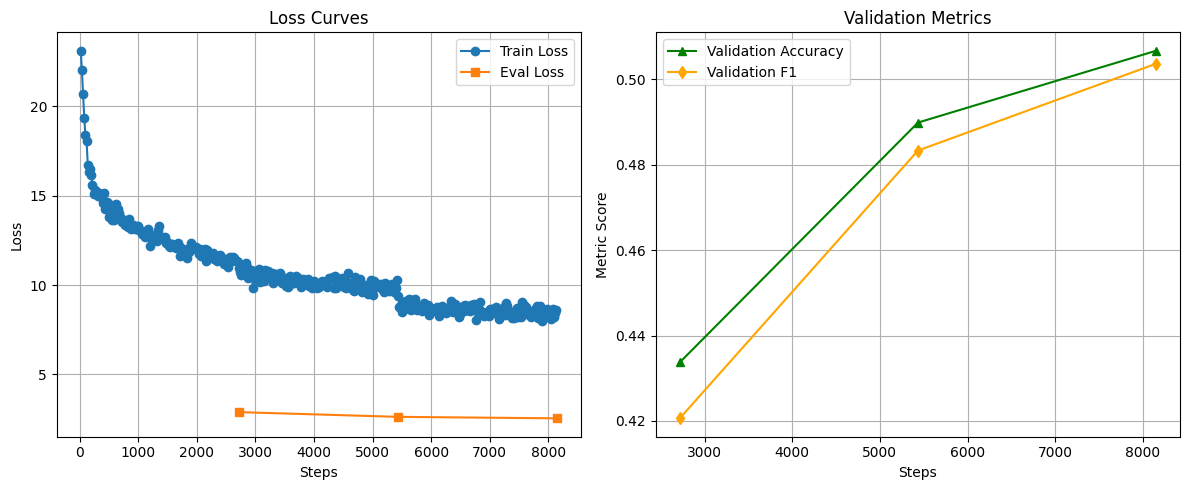

In [36]:
# 3. Plotting
plt.figure(figsize=(12, 5))

# Plot Loss if available
if not hist_train.empty or not eval_df.empty:
  plt.subplot(1, 2, 1)
  if not hist_train.empty:
    plt.plot(hist_train["step"], hist_train["loss"], label="Train Loss", marker="o")
  if not eval_df.empty:
    plt.plot(
        eval_df["step"], eval_df["eval_loss"], label="Eval Loss", marker="s"
    )
  plt.xlabel("Steps")
  plt.ylabel("Loss")
  plt.title("Loss Curves")
  plt.legend()
  plt.grid(True)

# Plot Validation Metrics (Accuracy / F1)
if not eval_df.empty:
  plt.subplot(1, 2, 2)
  if "eval_accuracy" in eval_df.columns:
    plt.plot(
        eval_df["step"],
        eval_df["eval_accuracy"],
        label="Validation Accuracy",
        marker="^",
        color="green",
    )
  if "eval_f1" in eval_df.columns:
    plt.plot(
        eval_df["step"],
        eval_df["eval_f1"],
        label="Validation F1",
        marker="d",
        color="orange",
    )
  plt.xlabel("Steps")
  plt.ylabel("Metric Score")
  plt.title("Validation Metrics")
  plt.legend()
  plt.grid(True)

plt.tight_layout()
plt.show()

In [37]:
# # Evaluate on the Test Dataset
# print("\n--- Evaluating on Test Set ---")
# test_results = trainer.evaluate(eval_dataset=tokenized_splits["validation"])
# print(test_results)

## Load the best saved model

In [38]:
# Extract the best checkpoint path from the trainer state
best_model_path = trainer.state.best_model_checkpoint

print("Best model checkpoint path:", best_model_path)
# Create a text-classification pipeline using your saved model
classifier = pipeline(
    "text-classification",
    model=best_model_path,
    device=device
)

print("Best model successfully loaded from:", best_model_path)

Best model checkpoint path: ./saved_model/checkpoint-8151


Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

Best model successfully loaded from: ./saved_model/checkpoint-8151


## Predictions

In [39]:
# Using train_df for testing
texts = train_df['text'].to_list()
true_labels = train_df['model'].to_list()
# Run predictions in batches
results = classifier(texts, batch_size=16)
predicted_labels = [res['label'] for res in results]

# Evaluate Accuracy
accuracy = accuracy_score(true_labels, predicted_labels)
print(f"\n--- Pipeline Evaluation Results ---")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(true_labels, predicted_labels, zero_division=0))


--- Pipeline Evaluation Results ---
Accuracy: 59.50%

Classification Report:
                        precision    recall  f1-score   support

        claude-fable-5       0.37      0.32      0.34       149
       claude-opus-4-6       0.79      0.74      0.76       150
       claude-opus-4-8       0.65      0.61      0.63       150
         claude-opus-5       0.85      0.79      0.82       150
       claude-sonnet-5       0.58      0.71      0.64       150
gemini-3.1-pro-preview       0.97      0.77      0.86       150
      gemini-3.6-flash       0.63      0.80      0.71       150
      gemini-3.7-flash       0.60      0.20      0.30       150
      gemini-3.8-flash       0.46      0.79      0.58       150
               glm-5.3       0.34      0.29      0.31       150
         glm-5.3-flash       0.31      0.40      0.35       150
               gpt-5.5       0.56      0.55      0.56       150
          gpt-5.6-luna       0.61      0.63      0.62       150
           gpt-5.6-sol   

## Submission

In [40]:
TEST_PATH = (
    INPUT_DIR / "competitions/name-that-llm/test.csv"
)

test_df = pd.read_csv(TEST_PATH)
print("Original training shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
test_df.head()

Original training shape: (3, 2)
Columns: ['id', 'text']


,id,text
0,00353fb1c541,"The more efficiently we use a resource, the mo..."
1,005f5a9a6139,"The Stern-Gerlach experiment, performed in 192..."
2,0062a53d5487,"Hundreds of millions of years ago, fluctuating..."


In [41]:
results = classifier(test_df["text"].to_list(),  batch_size=16)

predicted_labels = [res['label'] for res in results]

# Submission
submission = pd.DataFrame({
    "id": test_df["id"].values,
    "model": predicted_labels
})

# Save
output_path = "/kaggle/working/submission.parquet"

submission.to_parquet(output_path, index=False)

print("\nSubmission preview:")
submission.head()


Submission preview:


,id,model
0,00353fb1c541,claude-opus-4-8
1,005f5a9a6139,gpt-5.6-terra
2,0062a53d5487,gemini-3.1-pro-preview
